# 01 — Découverte des données Telco

Explorer les données brutes avec les composants réutilisables de `telco_churn`.
Ce notebook reprend la progression du notebook BNPL : chargement, aperçu,
profil des colonnes, synthèse de qualité et visualisation.

**En complément :** exploration du pilote, statistiques descriptives et comparaison des schémas.
Les observations sont descriptives : aucune transformation, modélisation ou estimation causale.

**Prérequis :** depuis la racine du projet, installer le package avec
`poetry install --with notebook,dev`, puis utiliser le kernel de cet environnement.
Les chemins sont définis dans les YAML ; `APP_ENV` sélectionne `dev`, `staging` ou `prod`.


## 1. Configuration et chargement des données brutes

`Settings` valide les chemins. `configure_logging` configure la console et le fichier de log.
`TelcoDataLoader` lit les CSV via pandas sans conversion explicite des dates ni nettoyage.
Les types et valeurs manquantes affichés dépendent des conventions de lecture de pandas.


In [1]:
import pandas as pd
from IPython.display import display

from telco_churn.data.loaders import TelcoDataLoader
from telco_churn.data.quality import DataQualityReport
from telco_churn.logging import configure_logging
from telco_churn.settings import Settings

settings = Settings.load()
configure_logging(settings)

loader = TelcoDataLoader(settings)
df = loader.load_raw("churn")
pilot_df = loader.load_raw("pilot")
quality_report = DataQualityReport(target_column="churn")
pilot_quality_report = DataQualityReport(target_column="churn_30d")

print(f"Environnement : {settings.environment}")

2026-11-11 10:40:40 | INFO     | data.loaders | Dataset=churn path=/Users/surelmanda/2-LLops-Databricks-Projects/Telco-Churn-Optimization/data/raw/churn_clients.csv rows=38689 columns=16
2026-11-11 10:40:40 | INFO     | data.loaders | Dataset=pilot path=/Users/surelmanda/2-LLops-Databricks-Projects/Telco-Churn-Optimization/data/raw/pilote_campagne_2023.csv rows=4000 columns=10


Environnement : dev


## 2. Aperçu des datasets

Examiner les premières lignes et les dimensions. Une ligne du fichier principal
contient une `snapshot_date` : vérifier ensuite si plusieurs observations décrivent
le même client. Le pilote possède des variables spécifiques, notamment `contacted`.


In [2]:
print("DATASET PRINCIPAL")
display(df.head())
print(f"Lignes : {df.shape[0]:,} | Colonnes : {df.shape[1]} | Cible : churn")

print("CAMPAGNE PILOTE")
display(pilot_df.head())
print(f"Lignes : {pilot_df.shape[0]:,} | Colonnes : {pilot_df.shape[1]} | Cible : churn_30d")

DATASET PRINCIPAL


,customer_id,snapshot_date,signup_date,age,contract,region,dept,channel,monthly_fee,data_gb,support_calls_3m,late_payments,nps,last_invoice_amount,retention_offer_declined,churn
0,102683,2024-10-31,2020-12-04,38.0,biannuel,OCC,2,partenaire,65.15,7.9,1,1,7.0,65.15,0,0
1,100127,2024-04-30,2020-05-25,40.0,mensuel,ARA,1,telephone,48.21,14.2,0,0,NaN,48.21,0,0
2,102042,2024-04-30,2024-01-06,21.0,mensuel,IDF,9,partenaire,49.09,5.8,1,0,10.0,49.09,0,0
3,101775,2024-02-29,2021-01-01,42.0,mensuel,OCC,7,web,60.29,26.4,3,0,NaN,60.29,0,0
4,103774,2024-06-30,2020-09-17,NaN,annuel,NAQ,42,telephone,52.09,1.8,1,0,NaN,52.09,1,0


Lignes : 38,689 | Colonnes : 16 | Cible : churn
CAMPAGNE PILOTE


,customer_id,age,contract,region,tenure_months,monthly_fee,support_calls_3m,late_payments,contacted,churn_30d
0,503815,45.0,mensuel,PACA,53,81.88,3,1,1,0
1,503993,53.0,annuel,IDF,57,46.29,0,1,1,0
2,501016,32.0,annuel,IDF,69,81.41,1,0,1,0
3,503707,40.0,mensuel,BRE,72,50.77,1,1,1,0
4,500949,38.0,mensuel,PACA,26,80.47,1,0,1,0


Lignes : 4,000 | Colonnes : 10 | Cible : churn_30d


## 3. Profil des colonnes

Types inférés, effectifs renseignés, valeurs manquantes et cardinalité.
Les valeurs uniques excluent les valeurs manquantes. Aucun type métier n'est imposé ici.

Le profil reprend BNPL : zéros, infinis, min/moyenne/médiane/max, écart-type et exemples.
Les valeurs atypiques sont repérées au-delà de 1,5 IQR ; ce sont des signaux exploratoires,
pas des erreurs avérées. Les taux de zéros et de valeurs atypiques utilisent les valeurs
numériques finies ; le taux de valeurs uniques utilise les valeurs non manquantes.


In [3]:
print("DATASET PRINCIPAL")
column_profile = quality_report.profile_dataset(df)
display(column_profile)

print("CAMPAGNE PILOTE")
pilot_column_profile = pilot_quality_report.profile_dataset(pilot_df)
display(pilot_column_profile)

2026-11-11 10:40:40 | INFO     | data.profiling | Computing dataset quality summary rows=38689 columns=16


DATASET PRINCIPAL


,Column,Type,Non-Null,Missing,% Missing,Cardinality,% Unique,Zeros,% Zeros,Infinite,Outliers,% Outliers,Min,Mean,Median,Max,Std Dev,Examples
0,nps,float64,12444,26245,67.84,11,0.09,9,0.07,0,9,0.07,-0.0,6.8029,7.0,10.0,1.9795,"[7.0, 10.0, 8.0, 9.0, 6.0]"
1,age,float64,36561,2128,5.50,72,0.20,115,0.31,0,469,1.28,-1.0,46.0,43.0,999.0,57.1067,"[38.0, 40.0, 21.0, 42.0, 58.0]"
2,monthly_fee,float64,36792,1897,4.90,8273,22.49,0,0.0,0,261,0.71,-109.28,60.5971,60.8,130.39,19.3073,"[65.15, 48.21, 49.09, 60.29, 52.09]"
3,customer_id,int64,38689,0,0.00,4000,10.34,0,0.0,0,0,0.0,100000.0,101999.2045,101998.0,103999.0,1152.2003,"[102683, 100127, 102042, 101775, 103774]"
4,snapshot_date,object,38689,0,0.00,12,0.03,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,"[2024-10-31, 2024-04-30, 2024-02-29, 2024-06-3..."
5,signup_date,object,38689,0,0.00,1787,4.62,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,"[2020-12-04, 2020-05-25, 2024-01-06, 2021-01-0..."
6,contract,object,38689,0,0.00,12,0.03,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,"[biannuel, mensuel, annuel, MENSUEL, Annuel, m..."
7,region,object,38689,0,0.00,7,0.02,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,"[OCC, ARA, IDF, NAQ, PACA, BRE, GES]"
8,dept,int64,38689,0,0.00,60,0.16,0,0.0,0,0,0.0,1.0,16.4566,10.0,60.0,16.4959,"[2, 1, 9, 7, 42]"
9,channel,object,38689,0,0.00,16,0.04,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,"[partenaire, telephone, web, boutique, BOUTIQU..."


2026-11-11 10:40:41 | INFO     | data.profiling | Computing dataset quality summary rows=4000 columns=10


CAMPAGNE PILOTE


,Column,Type,Non-Null,Missing,% Missing,Cardinality,% Unique,Zeros,% Zeros,Infinite,Outliers,% Outliers,Min,Mean,Median,Max,Std Dev,Examples
0,customer_id,int64,4000,0,0.0,4000,100.00,0,0.0,0,0,0.0,500000.0,501999.5,501999.5,503999.0,1154.8449,"[503815, 503993, 501016, 503707, 500949]"
1,age,float64,4000,0,0.0,68,1.70,0,0.0,0,20,0.5,18.0,42.2615,42.0,90.0,13.4896,"[45.0, 53.0, 32.0, 40.0, 38.0]"
2,contract,object,4000,0,0.0,3,0.07,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,"[mensuel, annuel, biannuel]"
3,region,object,4000,0,0.0,7,0.18,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,"[PACA, IDF, BRE, NAQ, ARA, OCC, GES]"
4,tenure_months,int64,4000,0,0.0,79,1.98,0,0.0,0,0,0.0,1.0,40.059,40.0,79.0,22.6033,"[53, 57, 69, 72, 26]"
5,monthly_fee,float64,4000,0,0.0,2956,73.90,0,0.0,0,13,0.33,15.0,59.8028,59.61,119.77,17.5649,"[81.88, 46.29, 81.41, 50.77, 80.47]"
6,support_calls_3m,int64,4000,0,0.0,10,0.25,1319,32.98,0,21,0.53,0.0,1.2052,1.0,9.0,1.2027,"[3, 0, 1, 2, 5]"
7,late_payments,int64,4000,0,0.0,5,0.12,2647,66.17,0,38,0.95,0.0,0.4183,0.0,4.0,0.653,"[1, 0, 2, 3, 4]"
8,contacted,int64,4000,0,0.0,2,0.05,1872,46.8,0,0,0.0,0.0,0.532,1.0,1.0,0.499,"[1, 0]"
9,churn_30d,int64,4000,0,0.0,2,0.05,3822,95.55,0,178,4.45,0.0,0.0445,0.0,1.0,0.2062,"[0, 1]"


## 4. Statistiques descriptives simples

`describe(include="all")` résume les colonnes numériques et catégorielles.
Certaines statistiques ne s'appliquent pas à tous les types, ce qui explique des
cellules vides dans le tableau. Les identifiants numériques ne sont pas des mesures métier.


In [4]:
print("DATASET PRINCIPAL")
display(df.describe(include="all").T)

print("CAMPAGNE PILOTE")
display(pilot_df.describe(include="all").T)

DATASET PRINCIPAL


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,38689.0,NaN,NaN,NaN,101999.204528,1152.200348,100000.0,100997.0,101998.0,102996.0,103999.0
snapshot_date,38689,12,2024-01-31,3494,NaN,NaN,NaN,NaN,NaN,NaN,NaN
signup_date,38689,1787,2019-11-24,93,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,36561.0,NaN,NaN,NaN,45.999973,57.10674,-1.0,33.0,43.0,52.0,999.0
contract,38689,12,mensuel,19359,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,38689,7,ARA,5807,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dept,38689.0,NaN,NaN,NaN,16.456641,16.49587,1.0,3.0,10.0,26.0,60.0
channel,38689,16,web,14915,NaN,NaN,NaN,NaN,NaN,NaN,NaN
monthly_fee,36792.0,NaN,NaN,NaN,60.597069,19.307341,-109.28,48.65,60.8,72.99,130.39
data_gb,38689.0,NaN,NaN,NaN,71.805027,766.455238,0.0,1.9,3.7,6.8,32154.0


CAMPAGNE PILOTE


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,4000.0,NaN,NaN,NaN,501999.5,1154.844867,500000.0,500999.75,501999.5,502999.25,503999.0
age,4000.0,NaN,NaN,NaN,42.2615,13.489574,18.0,33.0,42.0,51.25,90.0
contract,4000,3,mensuel,2171,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,4000,7,GES,611,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure_months,4000.0,NaN,NaN,NaN,40.059,22.603324,1.0,20.0,40.0,60.0,79.0
monthly_fee,4000.0,NaN,NaN,NaN,59.802842,17.564855,15.0,47.76,59.61,72.085,119.77
support_calls_3m,4000.0,NaN,NaN,NaN,1.20525,1.202699,0.0,0.0,1.0,2.0,9.0
late_payments,4000.0,NaN,NaN,NaN,0.41825,0.653011,0.0,0.0,0.0,1.0,4.0
contacted,4000.0,NaN,NaN,NaN,0.532,0.499037,0.0,0.0,1.0,1.0,1.0
churn_30d,4000.0,NaN,NaN,NaN,0.0445,0.206229,0.0,0.0,0.0,0.0,1.0


## 5. Synthèse de qualité

Les doublons ci-dessous sont des lignes entièrement identiques, pas des identifiants répétés.
Les distributions de `churn` et `churn_30d` sont présentées séparément : leurs horizons
et populations ne sont pas supposés équivalents. Les classes excluent les cibles manquantes ; les taux utilisent toutes les lignes comme dénominateur.
Le rapport compte séparément ces cibles manquantes (`target_missing_count`).


In [5]:
report = quality_report.build(df)
pilot_report = pilot_quality_report.build(pilot_df)

summary_columns = ["n_rows", "n_columns", "n_duplicate_rows", "n_missing_values_total"]
summary = pd.DataFrame(
    {
        "principal": {key: report[key] for key in summary_columns},
        "pilote": {key: pilot_report[key] for key in summary_columns},
    }
).T
display(summary)

print("Valeurs manquantes — principal")
display(column_profile.loc[column_profile["Missing"] > 0])
print("Valeurs manquantes — pilote")
display(pilot_column_profile.loc[pilot_column_profile["Missing"] > 0])
print("Distribution de churn")
display(pd.DataFrame.from_dict(report["target_distribution"], orient="index").rename_axis("churn"))
print("Distribution de churn_30d")
display(
    pd.DataFrame.from_dict(pilot_report["target_distribution"], orient="index").rename_axis(
        "churn_30d"
    )
)
quality_report.log(report, pipeline="discovery.churn")
pilot_quality_report.log(pilot_report, pipeline="discovery.pilot")

,n_rows,n_columns,n_duplicate_rows,n_missing_values_total
principal,38689,16,60,30270
pilote,4000,10,0,0


Valeurs manquantes — principal


,Column,Type,Non-Null,Missing,% Missing,Cardinality,% Unique,Zeros,% Zeros,Infinite,Outliers,% Outliers,Min,Mean,Median,Max,Std Dev,Examples
0,nps,float64,12444,26245,67.84,11,0.09,9,0.07,0,9,0.07,-0.0,6.8029,7.0,10.0,1.9795,"[7.0, 10.0, 8.0, 9.0, 6.0]"
1,age,float64,36561,2128,5.50,72,0.20,115,0.31,0,469,1.28,-1.0,46.0,43.0,999.0,57.1067,"[38.0, 40.0, 21.0, 42.0, 58.0]"
2,monthly_fee,float64,36792,1897,4.90,8273,22.49,0,0.0,0,261,0.71,-109.28,60.5971,60.8,130.39,19.3073,"[65.15, 48.21, 49.09, 60.29, 52.09]"


Valeurs manquantes — pilote


,Column,Type,Non-Null,Missing,% Missing,Cardinality,% Unique,Zeros,% Zeros,Infinite,Outliers,% Outliers,Min,Mean,Median,Max,Std Dev,Examples


Distribution de churn


,count,rate
churn,,
0,37525,0.969914
1,1164,0.030086


Distribution de churn_30d


,count,rate
churn_30d,,
0,3822,0.9555
1,178,0.0445


2026-11-11 10:40:41 | INFO     | discovery.churn | Data quality: rows=38689 columns=16 duplicates=60 missing_total=30270
2026-11-11 10:40:41 | WARNING  | discovery.churn | Missing values by column: {'age': 2128, 'monthly_fee': 1897, 'nps': 26245}
2026-11-11 10:40:41 | INFO     | discovery.churn | Target distribution: {'0': {'count': 37525, 'rate': 0.9699139290237535}, '1': {'count': 1164, 'rate': 0.03008607097624648}}
2026-11-11 10:40:41 | INFO     | discovery.pilot | Data quality: rows=4000 columns=10 duplicates=0 missing_total=0
2026-11-11 10:40:41 | INFO     | discovery.pilot | Target distribution: {'0': {'count': 3822, 'rate': 0.9555}, '1': {'count': 178, 'rate': 0.0445}}


## 6. Synthèse visuelle

Afficher les taux de valeurs manquantes et les effectifs des cibles,
à partir des mêmes composants que ceux utilisables dans les futurs pipelines.

Le tableau de bord comprend quatre panneaux : indicateurs globaux, valeurs manquantes,
distribution de la cible et types des colonnes. Pour sauvegarder :
`quality_report.show(df, save_path=settings.project_root / "reports/figures/churn_quality.png")`.


DATASET PRINCIPAL


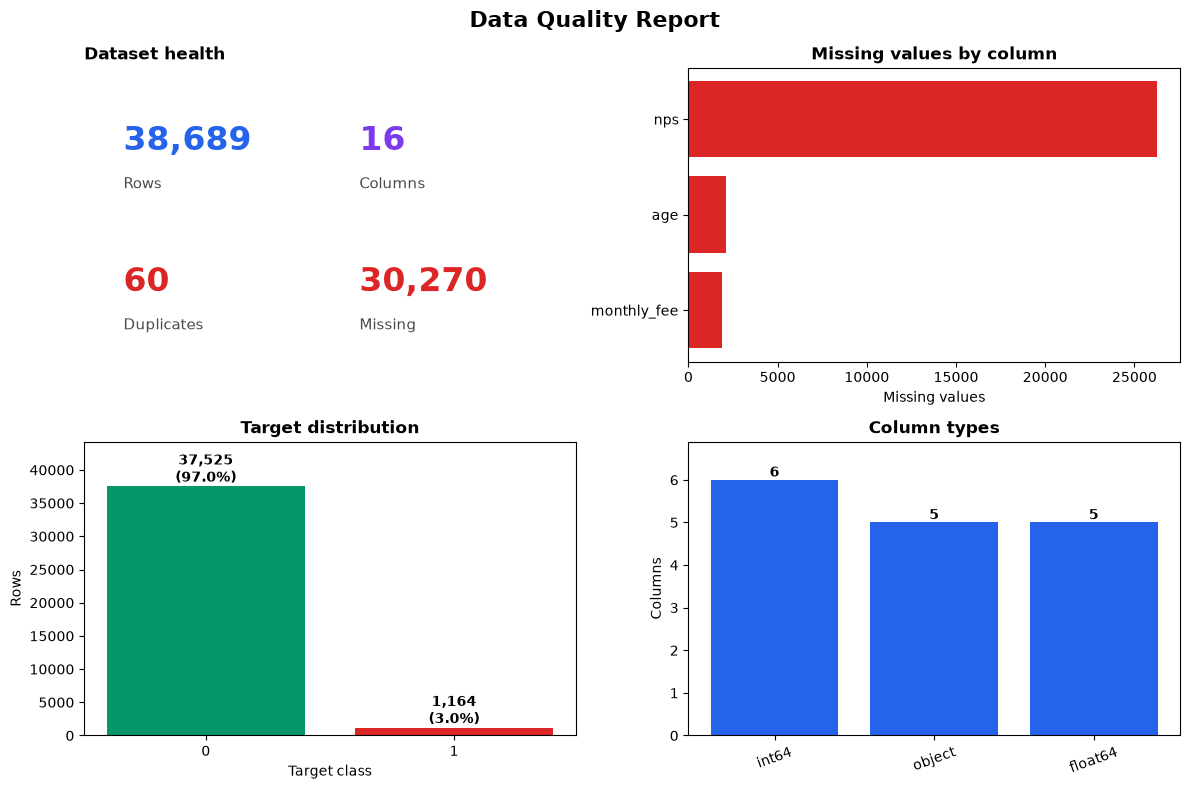

CAMPAGNE PILOTE


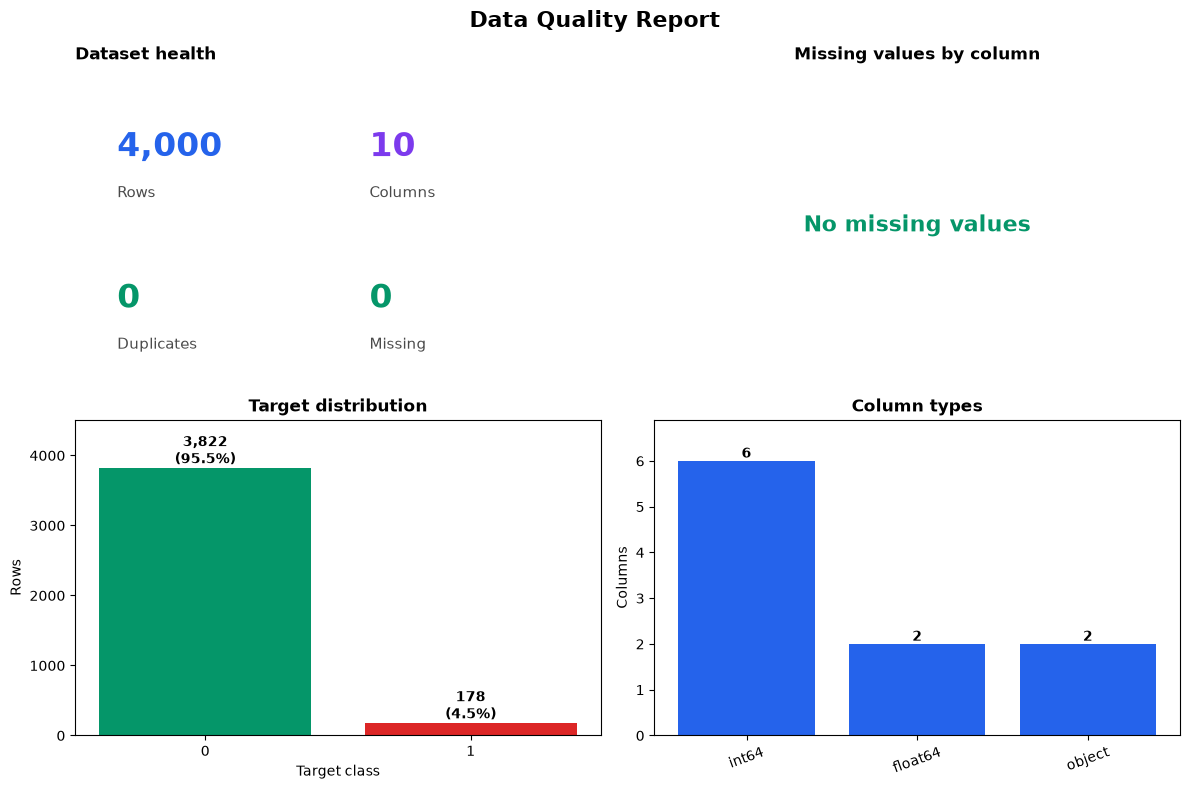

In [6]:
print("DATASET PRINCIPAL")
quality_report.show(df)

print("CAMPAGNE PILOTE")
pilot_quality_report.show(pilot_df)

## 7. Complément Telco : comparer les structures

Comparer les colonnes communes et spécifiques, sans fusionner les datasets.
Un nom identique ne garantit ni une définition identique ni la comparabilité des populations.


In [7]:
schema_comparison = pd.concat(
    [
        df.dtypes.astype(str).rename("principal"),
        pilot_df.dtypes.astype(str).rename("pilote"),
    ],
    axis=1,
).fillna("absente")
display(schema_comparison)

print("Colonnes communes :", sorted(set(df.columns) & set(pilot_df.columns)))
print("Spécifiques au principal :", sorted(set(df.columns) - set(pilot_df.columns)))
print("Spécifiques au pilote :", sorted(set(pilot_df.columns) - set(df.columns)))

,principal,pilote
customer_id,int64,int64
snapshot_date,object,absente
signup_date,object,absente
age,float64,float64
contract,object,object
region,object,object
dept,int64,absente
channel,object,absente
monthly_fee,float64,float64
data_gb,float64,absente


Colonnes communes : ['age', 'contract', 'customer_id', 'late_payments', 'monthly_fee', 'region', 'support_calls_3m']
Spécifiques au principal : ['channel', 'churn', 'data_gb', 'dept', 'last_invoice_amount', 'nps', 'retention_offer_declined', 'signup_date', 'snapshot_date']
Spécifiques au pilote : ['churn_30d', 'contacted', 'tenure_months']


## 8. Observations et points à confirmer

Première exécution sur les fichiers actuels :

| Source | Lignes | Colonnes | Lignes entièrement dupliquées | Cellules manquantes |
|---|---:|---:|---:|---:|
| Principal | 38 689 | 16 | 60 | 30 270 |
| Pilote | 4 000 | 10 | 0 | 0 |

Le principal nécessite une investigation des valeurs manquantes et des doublons.
L'absence de valeurs manquantes détectées dans le pilote ne garantit pas sa qualité métier.
Ces chiffres sont un constat sur les fichiers actuels ; les tableaux calculés ci-dessus
font référence si les sources changent.

À compléter après lecture des tableaux :

- Dimensions, types et premières valeurs manquantes observées dans chaque source.
- Colonnes ayant des types surprenants ou des valeurs nécessitant une investigation.
- Unité d'observation : client ou photographie d'un client à une date donnée ?
- Définition et horizon de `churn`, comparés à `churn_30d` dans le pilote.
- Signification de `contacted` et modalités de constitution de la campagne pilote.

Les profils comptent les valeurs manquantes reconnues par pandas ; ils ne valident pas
les codes métier ou les chaînes composées d'espaces. Les diagnostics ne corrigent aucune donnée.
La qualité détaillée sera étudiée dans le notebook suivant, après validation de cette découverte.
